# 03 — Pré-processamento: Colunas Categóricas

O notebook 02 terminou com uma regressão logística que usava só as **5 colunas numéricas**: acurácia de **81,3%**, mas encontrando só **38%** das pessoas de renda alta. As colunas **categóricas** ficaram de fora, e o notebook 01 mostrou que algumas delas, como estado civil e profissão, estão entre as mais informativas.

O problema é que modelos só fazem contas com **números**, e essas colunas são **texto**. Neste notebook vamos:
- Ver por que **numerar** as categorias (1, 2, 3...) é uma má ideia
- Aprender o **one-hot encoding**
- Tratar os **valores ausentes** como uma categoria própria
- Agrupar **categorias raras** e lidar com categorias **nunca vistas**
- Juntar tudo num **`ColumnTransformer`** dentro do `Pipeline`
- Descobrir quais colunas categóricas ajudam mais, e testar uma ideia que **não** funciona

> Lembrete: execute as células em ordem com `Shift + Enter`.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# Ferramentas novas deste notebook:
from sklearn.preprocessing import OrdinalEncoder   # transforma cada categoria em um número inteiro
from sklearn.preprocessing import OneHotEncoder    # transforma cada categoria em uma coluna de 0/1
from sklearn.impute import SimpleImputer           # preenche valores ausentes
from sklearn.compose import ColumnTransformer      # aplica tratamentos diferentes a colunas diferentes

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 100

df = fetch_openml("adult", version=2, as_frame=True).frame
X = df.drop(columns="class")
y = (df["class"] == ">50K").astype(int)

# O MESMO teste estratificado do notebook 02, e ele continua guardado.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

colunas_numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
# education fica de fora: é a mesma informação de education-num (notebook 01, seção 9). Vamos confirmar isso na seção 8.
colunas_categoricas = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]

print(f"Treino: {len(X_train)} pessoas   Teste (guardado): {len(X_test)} pessoas")

Treino: 39073 pessoas   Teste (guardado): 9769 pessoas


Para comparar os modelos, vamos usar uma pequena função que calcula, com validação cruzada, as duas medidas do notebook 02: a **acurácia** e a **porcentagem das pessoas de renda alta que o modelo encontra**.

In [2]:
def avaliar(modelo, colunas):
    """Validação cruzada: devolve a acurácia média, o desvio e a % de renda alta encontrada."""
    acuracias = cross_val_score(modelo, X_train[colunas], y_train, cv=cv, scoring="accuracy")
    # As previsões "fora da dobra" de cada pessoa, para contar quantas de renda alta foram encontradas.
    previsoes = cross_val_predict(modelo, X_train[colunas], y_train, cv=cv)
    vn, fp, fn, vp = confusion_matrix(y_train, previsoes).ravel()
    # Um dicionário com os resultados: fica fácil de virar uma linha de tabela depois.
    return {
        "acurácia": acuracias.mean(),
        "± desvio": acuracias.std(),
        "renda alta encontrada": vp / (vp + fn),
    }


# O ponto de partida: a logística do notebook 02, só com as numéricas.
logistica_numericas = Pipeline([
    ("padronizar", StandardScaler()),
    ("modelo", LogisticRegression()),
])
resultados = {}   # vamos guardar aqui o resultado de cada ideia testada
resultados["Só numéricas (nb 02)"] = avaliar(logistica_numericas, colunas_numericas)
pd.DataFrame(resultados).T

,acurácia,± desvio,renda alta encontrada
Só numéricas (nb 02),0.8128,0.0055,0.3815


**Conclusão:** reproduzimos o resultado do notebook 02: acurácia de **81,28%** e **38,2%** das pessoas de renda alta encontradas. Esse é o número a vencer.

## 🎓 Conceito: codificação de categorias

Para usar uma coluna de texto num modelo, precisamos **codificá-la** em números. Existem duas formas principais:

1. **Codificação ordinal:** dar um número a cada categoria. Por exemplo, `Adm-clerical` = 0, `Armed-Forces` = 1, `Craft-repair` = 2...
2. **One-hot encoding:** criar **uma coluna de 0/1 para cada categoria** (seção 3).

A codificação ordinal parece a mais natural, mas tem uma armadilha: ela **inventa uma ordem** que não existe. Para um modelo linear, "profissão = 4" vira "o dobro de profissão = 2", e a distância entre `Craft-repair` (2) e `Exec-managerial` (3) é a mesma que entre `Exec-managerial` (3) e `Farming-fishing` (4). Nada disso faz sentido para categorias **nominais** (lembre do notebook 01: as que não têm ordem natural).

Analogia: é como numerar as cores de uma caixa de lápis em ordem alfabética (amarelo = 1, azul = 2, verde = 3...) e depois concluir que "verde é o triplo de amarelo".

## 2. A ideia ingênua: numerar as categorias

In [3]:
# O OrdinalEncoder atribui números às categorias em ordem ALFABÉTICA.
codificador_ordinal = OrdinalEncoder()
codificador_ordinal.fit(X_train[["occupation"]])

# categories_ é uma lista com as categorias de cada coluna; [0] pega as da única coluna que passamos.
# O nan no fim é o valor ausente: o OrdinalEncoder não dá um número a ele, apenas o mantém vazio.
# Vamos aprender a preencher os ausentes na seção 3.
for numero, categoria in enumerate(codificador_ordinal.categories_[0]):
    print(f"{numero:>2} -> {categoria}")   # :>2 alinha o número à direita em 2 espaços

 0 -> Adm-clerical
 1 -> Armed-Forces
 2 -> Craft-repair
 3 -> Exec-managerial
 4 -> Farming-fishing
 5 -> Handlers-cleaners
 6 -> Machine-op-inspct
 7 -> Other-service
 8 -> Priv-house-serv
 9 -> Prof-specialty
10 -> Protective-serv
11 -> Sales
12 -> Tech-support
13 -> Transport-moving
14 -> nan


Vamos ver o efeito disso num modelo. Para comparar de forma justa, colocamos o `OrdinalEncoder` dentro de um pipeline completo (usando o `ColumnTransformer`, que será explicado em detalhes na seção 4).

In [4]:
logistica_ordinal = Pipeline([
    ("preparar", ColumnTransformer([
        ("numericas", StandardScaler(), colunas_numericas),
        ("categoricas", Pipeline([
            # Preenche os ausentes com o texto "Desconhecido" (explicado na seção 3).
            ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
            # handle_unknown/unknown_value: uma categoria nunca vista vira -1 (detalhes na seção 7).
            ("numerar", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
            ("padronizar", StandardScaler()),
        ]), colunas_categoricas),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])

resultados["Numéricas + categóricas numeradas"] = avaliar(logistica_ordinal, colunas_numericas + colunas_categoricas)
pd.DataFrame(resultados).T

,acurácia,± desvio,renda alta encontrada
Só numéricas (nb 02),0.8128,0.0055,0.3815
Numéricas + categóricas numeradas,0.8232,0.0046,0.4445


**Conclusão:** com as categorias numeradas, a acurácia subiu um pouco, de 81,28% para **82,32%**, e a renda alta encontrada foi de 38,2% para **44,5%**. Alguma informação passou, mas pouca. O modelo só consegue dizer "quanto **maior** o número da profissão, mais (ou menos) renda", e como os números seguem a ordem **alfabética**, essa regra não tem significado. Precisamos de uma codificação que respeite o fato de que as categorias **não têm ordem**.

## 🎓 Conceito: one-hot encoding

O **one-hot encoding** cria **uma coluna nova para cada categoria**. Em cada linha, a coluna da categoria da pessoa recebe **1**, e todas as outras recebem **0**. O nome vem disso: só uma coluna fica "acesa" (*hot*).

| sex | → | sex_Female | sex_Male |
|---|---|---|---|
| Male | | 0 | 1 |
| Female | | 1 | 0 |
| Male | | 0 | 1 |

Assim, cada categoria ganha **o seu próprio coeficiente** na regressão logística. O modelo pode aprender, por exemplo, que `Exec-managerial` aumenta muito a chance de renda alta, `Sales` aumenta um pouco e `Handlers-cleaners` diminui, sem nenhuma ordem inventada.

Analogia: é como um formulário de "marque com X", com uma caixinha por opção, em vez de pedir para a pessoa escrever um número.

O custo: uma coluna com 15 profissões vira **15 colunas**. Com muitas categorias raras (como os 41 países), a tabela fica larga e cheia de zeros. Vamos lidar com isso na seção 7.

## 3. One-hot encoding na prática

In [5]:
amostra = X_train[["sex", "workclass"]].head(5)
display(amostra)

# sparse_output=False devolve uma tabela comum. O padrão é uma matriz "esparsa", que guarda só as
# posições dos 1s para economizar memória (ótimo para os modelos, ruim para nós olharmos).
codificador = OneHotEncoder(sparse_output=False)
codificador.fit(amostra)

# get_feature_names_out() devolve os nomes das colunas criadas, no formato "coluna_categoria".
pd.DataFrame(
    codificador.transform(amostra),
    columns=codificador.get_feature_names_out(),
    index=amostra.index,
).astype(int)

,sex,workclass
34342,Male,Private
18559,Female,Private
12477,Male,Private
560,Female,Private
3427,Male,Private


,sex_Female,sex_Male,workclass_Private
34342,0,1,1
18559,1,0,1
12477,0,1,1
560,1,0,1
3427,0,1,1


**Conclusão:** cada linha tem exatamente **um 1** entre as colunas de `sex` e **um 1** entre as de `workclass`. Repare que o encoder só criou colunas para as categorias que **viu** na amostra (só 2 tipos de `workclass` apareceram nessas 5 linhas). É por isso que ele precisa **aprender** (`fit`) as categorias, e só com o treino, para evitar vazamento. Repare também na coluna `workclass_nan`: o valor ausente virou uma "categoria" com o nome `nan`, que é pouco claro. Vamos dar um nome melhor a ele.

## 🎓 Conceito: preenchendo valores ausentes (imputação)

**Imputar** é preencher um valor ausente com algum valor escolhido. As estratégias mais comuns são:
- **Numéricas:** a média ou a mediana da coluna.
- **Categóricas:** a categoria mais frequente, ou uma **categoria nova**, como "Desconhecido".

No notebook 01, vimos que a ausência em `workclass` e `occupation` é **informativa**: entre quem não informou a profissão, só 9,4% ganham mais de 50 mil, contra 24,8% dos demais. Se preenchêssemos com a profissão mais frequente, **apagaríamos** essa informação. Por isso, vamos criar a categoria **"Desconhecido"**: com o one-hot, ela vira uma coluna própria, e o modelo pode aprender um coeficiente para ela.

O `SimpleImputer` também **aprende** com os dados (a média, a mediana ou a categoria mais frequente). Por isso, ele também vai dentro do pipeline.

In [6]:
# strategy="constant": preenche todo valor ausente com o mesmo valor, o fill_value.
imputador = SimpleImputer(strategy="constant", fill_value="Desconhecido")

colunas_com_ausentes = ["workclass", "occupation", "native-country"]
# Quatro exemplos com ausentes diferentes. pd.concat junta tabelas uma embaixo da outra.
linhas_com_ausentes = pd.concat([
    X_train.loc[X_train["workclass"].isna(), colunas_com_ausentes].head(2),           # sem workclass e sem occupation
    X_train.loc[X_train["workclass"] == "Never-worked", colunas_com_ausentes].head(1),  # nunca trabalhou: sem occupation
    X_train.loc[X_train["native-country"].isna(), colunas_com_ausentes].head(1),      # sem país
])
display(linhas_com_ausentes)

pd.DataFrame(
    imputador.fit_transform(linhas_com_ausentes),   # fit_transform = fit e transform de uma vez
    columns=colunas_com_ausentes,
    index=linhas_com_ausentes.index,
)

,workclass,occupation,native-country
23445,NaN,NaN,United-States
25103,NaN,NaN,United-States
48595,Never-worked,NaN,United-States
23565,Federal-gov,Prof-specialty,NaN


,workclass,occupation,native-country
23445,Desconhecido,Desconhecido,United-States
25103,Desconhecido,Desconhecido,United-States
48595,Never-worked,Desconhecido,United-States
23565,Federal-gov,Prof-specialty,Desconhecido


**Conclusão:** os valores ausentes viraram **"Desconhecido"**, e o resto ficou igual. Agora, em sequência, o `SimpleImputer` e o `OneHotEncoder` criam as colunas `workclass_Desconhecido`, `occupation_Desconhecido` e `native-country_Desconhecido`.

## 🎓 Conceito: ColumnTransformer

Agora temos tratamentos **diferentes** para tipos de coluna diferentes:
- **Numéricas:** padronizar (`StandardScaler`).
- **Categóricas:** preencher ausentes (`SimpleImputer`) e depois fazer o one-hot (`OneHotEncoder`).

O **`ColumnTransformer`** faz isso: recebe uma lista de "receitas", cada uma com **um nome, um transformador e as colunas** em que ele se aplica. Ele aplica cada receita às suas colunas e **junta** os resultados lado a lado numa tabela só.

Analogia: uma cozinha com estações. Os legumes vão para a estação de cortar, as carnes para a grelha, e no final tudo se junta no mesmo prato.

Como o `ColumnTransformer` é um transformador como os outros, ele entra no `Pipeline` como a primeira etapa. Todo o pré-processamento **aprende só com o treino** de cada dobra, como no ML-01.

```
Pipeline
├── preparar: ColumnTransformer
│   ├── numericas   -> StandardScaler                      (5 colunas)
│   └── categoricas -> SimpleImputer -> OneHotEncoder      (7 colunas)
└── modelo: LogisticRegression
```

## 4. O pipeline completo

In [7]:
# As etapas das colunas categóricas formam um pequeno pipeline próprio.
preparar_categoricas = Pipeline([
    ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
    # handle_unknown="ignore": se aparecer uma categoria nunca vista no treino, todas as colunas dela ficam 0
    # (em vez de dar erro). Veja a seção 7.
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preparar = ColumnTransformer([
    # (nome, transformador, colunas)
    ("numericas", StandardScaler(), colunas_numericas),
    ("categoricas", preparar_categoricas, colunas_categoricas),
])

logistica_one_hot = Pipeline([
    ("preparar", preparar),
    # max_iter: o número máximo de passos do algoritmo de treino. Com muitas colunas, o padrão (100)
    # às vezes não basta para ele chegar ao melhor resultado, e o scikit-learn mostra um aviso.
    ("modelo", LogisticRegression(max_iter=1000)),
])

# Para entender o que acontece, treinamos uma vez e olhamos a tabela que chega ao modelo.
logistica_one_hot.fit(X_train, y_train)
nomes_colunas = logistica_one_hot.named_steps["preparar"].get_feature_names_out()
print(f"Colunas de entrada: {len(colunas_numericas) + len(colunas_categoricas)}")
print(f"Colunas que chegam ao modelo depois do pré-processamento: {len(nomes_colunas)}")
print("Algumas delas:", list(nomes_colunas[:7]), "...")

Colunas de entrada: 12
Colunas que chegam ao modelo depois do pré-processamento: 91
Algumas delas: ['numericas__age', 'numericas__education-num', 'numericas__capital-gain', 'numericas__capital-loss', 'numericas__hours-per-week', 'categoricas__workclass_Desconhecido', 'categoricas__workclass_Federal-gov'] ...


In [8]:
resultados["Numéricas + one-hot"] = avaliar(logistica_one_hot, colunas_numericas + colunas_categoricas)
pd.DataFrame(resultados).T

,acurácia,± desvio,renda alta encontrada
Só numéricas (nb 02),0.8128,0.0055,0.3815
Numéricas + categóricas numeradas,0.8232,0.0046,0.4445
Numéricas + one-hot,0.8514,0.0049,0.6005


**Conclusão:** as 12 colunas de entrada viraram **91 colunas** depois do one-hot, e o salto no resultado foi grande:
- **Acurácia:** de 81,28% (só numéricas) para **85,14%**. A codificação ordinal tinha chegado a 82,32%.
- **Renda alta encontrada:** de 38,2% para **60,0%**. O modelo agora encontra a maioria das pessoas que estamos procurando.

As mesmas informações, codificadas de outro jeito, renderam muito mais. **A forma de apresentar os dados ao modelo importa tanto quanto os próprios dados.**

## 5. Quais colunas categóricas ajudam mais?

Vamos adicionar **uma coluna categórica de cada vez** às numéricas e ver quanto cada uma melhora o modelo.

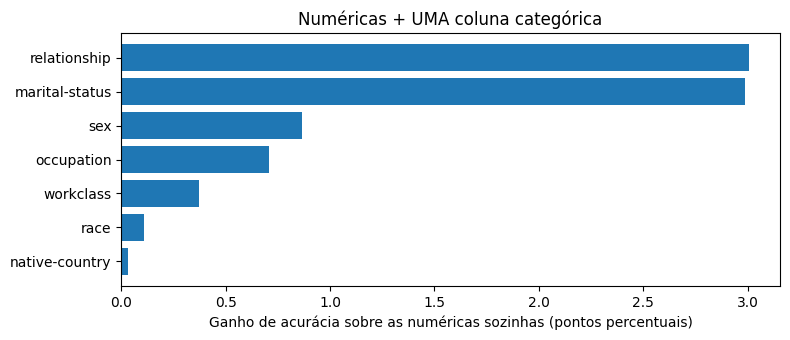

,acurácia,± desvio,renda alta encontrada,ganho (pontos percentuais)
relationship,0.8428,0.0038,0.5648,3.0046
marital-status,0.8427,0.0037,0.5673,2.9893
sex,0.8214,0.0047,0.4242,0.8676
occupation,0.8198,0.0053,0.4192,0.7089
workclass,0.8165,0.0051,0.3929,0.3711
race,0.8138,0.0062,0.3886,0.1075
native-country,0.8131,0.0054,0.3828,0.0307


In [9]:
def logistica_com(categoricas):
    """Monta o pipeline do one-hot para uma lista qualquer de colunas categóricas."""
    return Pipeline([
        ("preparar", ColumnTransformer([
            ("numericas", StandardScaler(), colunas_numericas),
            ("categoricas", Pipeline([
                ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
                ("one_hot", OneHotEncoder(handle_unknown="ignore")),
            ]), categoricas),
        ])),
        ("modelo", LogisticRegression(max_iter=1000)),
    ])


uma_de_cada_vez = {}
for coluna in colunas_categoricas:
    uma_de_cada_vez[coluna] = avaliar(logistica_com([coluna]), colunas_numericas + [coluna])

tabela_colunas = pd.DataFrame(uma_de_cada_vez).T.sort_values("acurácia")
# Quanto cada coluna acrescenta em relação às numéricas sozinhas (em pontos percentuais).
tabela_colunas["ganho (pontos percentuais)"] = (tabela_colunas["acurácia"] - resultados["Só numéricas (nb 02)"]["acurácia"]) * 100

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(tabela_colunas.index, tabela_colunas["ganho (pontos percentuais)"])
ax.set_xlabel("Ganho de acurácia sobre as numéricas sozinhas (pontos percentuais)")
ax.set_title("Numéricas + UMA coluna categórica")
plt.tight_layout()
plt.show()

tabela_colunas.sort_values("acurácia", ascending=False)

**Conclusão:** o ranking confirma a análise exploratória do notebook 01:
- **`relationship` e `marital-status` são, de longe, as mais úteis:** cada uma, sozinha, acrescenta **~3 pontos** de acurácia (84,28% e 84,27%) e leva a renda alta encontrada de 38% para **~57%**. As duas estão empatadas porque carregam quase a mesma informação (estar casado ou não).
- **`sex` (+0,87 ponto)** e **`occupation` (+0,71)** vêm em seguida.
- **`race` (+0,11)** e **`native-country` (+0,03)** quase não ajudam. Lembre do notebook 01: 91% das pessoas são dos Estados Unidos, então o país diz pouco sobre a maioria.

Repare que a soma dos ganhos individuais (~8,1 pontos) é maior que o ganho do modelo completo (~3,9 pontos). As colunas **se sobrepõem**: `relationship` e `marital-status` contam quase a mesma história, então colocar a segunda depois da primeira acrescenta pouco.

## 6. One-hot × numerar: a comparação

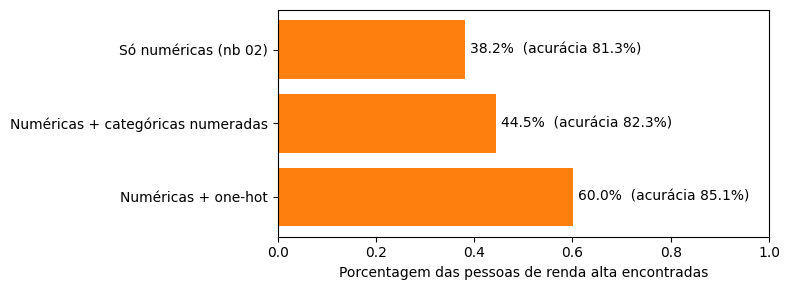

In [10]:
comparacao = pd.DataFrame(resultados).T
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(comparacao.index, comparacao["renda alta encontrada"], color="tab:orange")
for i, valor in enumerate(comparacao["renda alta encontrada"]):
    ax.text(valor + 0.01, i, f"{valor:.1%}  (acurácia {comparacao['acurácia'].iloc[i]:.1%})", va="center")
ax.set_xlim(0, 1)
ax.set_xlabel("Porcentagem das pessoas de renda alta encontradas")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Conclusão:** a comparação lado a lado deixa claro o efeito da codificação. Com as **mesmas** 12 colunas, o modelo com categorias **numeradas** encontra 44,5% das pessoas de renda alta, e o com **one-hot** encontra **60,0%**. A acurácia vai de 82,3% para 85,1%. Para colunas nominais, o one-hot é a escolha certa.

## 7. Categorias raras e categorias nunca vistas

O one-hot criou uma coluna para **cada** país, inclusive os que aparecem pouquíssimas vezes. Vamos olhar as categorias mais raras do treino:

In [11]:
paises_treino = X_train["native-country"].value_counts()
print(f"Países no treino: {paises_treino.size}")
print(f"Países com menos de 50 pessoas: {(paises_treino < 50).sum()}")
paises_treino.tail(6)

Países no treino: 41
Países com menos de 50 pessoas: 19


native-country
Scotland              19
Yugoslavia            19
Honduras              17
Laos                  17
Hungary               16
Holand-Netherlands     1
Name: count, dtype: int64

`Holand-Netherlands` aparece **uma única vez** no treino. Um coeficiente aprendido com uma pessoa só não é confiável: é puro ruído. E há um problema mais sério: o que acontece quando o modelo, já em uso, recebe uma pessoa de um país que **nunca** apareceu no treino, como o Brasil?

## 🎓 Conceito: categorias raras e desconhecidas

O `OneHotEncoder` tem duas opções para isso:
- **`min_frequency=50`:** categorias com menos de 50 pessoas no treino são **agrupadas** numa única coluna, a categoria "infrequente" (`infrequent_sklearn`). Os países raros passam a compartilhar um único coeficiente, aprendido com várias centenas de pessoas em vez de uma ou duas.
- **`handle_unknown`:** o que fazer com uma categoria **nunca vista**:
  - `"error"` (o padrão): dá erro. O modelo "quebra" em produção.
  - `"ignore"`: todas as colunas daquela variável ficam 0. É como dizer "não sei nada sobre o país dessa pessoa".
  - `"infrequent_if_exist"`: trata a categoria nova como **infrequente**. É o mais razoável: um país desconhecido provavelmente se parece mais com os países raros do que com os comuns.

Analogia: numa pesquisa de "qual seu esporte favorito?", as respostas com pouquíssimos votos vão para a linha "Outros". E se alguém responder um esporte que ninguém nunca mencionou, ele também vai para "Outros".

In [12]:
logistica_raras = Pipeline([
    ("preparar", ColumnTransformer([
        ("numericas", StandardScaler(), colunas_numericas),
        ("categoricas", Pipeline([
            ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
            ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
        ]), colunas_categoricas),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])

logistica_raras.fit(X_train, y_train)
nomes_raras = logistica_raras.named_steps["preparar"].get_feature_names_out()
print(f"Colunas depois do one-hot: {len(nomes_colunas)} -> {len(nomes_raras)} com min_frequency=50")
# Uma list comprehension com "if": só os nomes que contêm o texto "infrequent".
print("Colunas de categorias agrupadas:", [nome for nome in nomes_raras if "infrequent" in nome])

resultados["Numéricas + one-hot (raras agrupadas)"] = avaliar(logistica_raras, colunas_numericas + colunas_categoricas)
pd.DataFrame(resultados).T

Colunas depois do one-hot: 91 -> 72 com min_frequency=50
Colunas de categorias agrupadas: ['categoricas__workclass_infrequent_sklearn', 'categoricas__marital-status_infrequent_sklearn', 'categoricas__occupation_infrequent_sklearn', 'categoricas__native-country_infrequent_sklearn']


,acurácia,± desvio,renda alta encontrada
Só numéricas (nb 02),0.8128,0.0055,0.3815
Numéricas + categóricas numeradas,0.8232,0.0046,0.4445
Numéricas + one-hot,0.8514,0.0049,0.6005
Numéricas + one-hot (raras agrupadas),0.8515,0.0047,0.6001


Agora, o teste com uma pessoa de um país que nunca apareceu no treino:

In [13]:
# .copy() cria uma cópia independente, para não alterar o X_train.
pessoa_nova = X_train.iloc[[0]].copy()   # [[0]] (com colchetes duplos) devolve uma TABELA de 1 linha
pessoa_nova["native-country"] = "Brazil"

# try/except: tenta executar o bloco "try"; se der erro, executa o bloco "except" em vez de parar o notebook.
modelo_rigido = logistica_com(colunas_categoricas)
# set_params muda um hiperparâmetro de uma etapa "lá dentro" do pipeline: os nomes das etapas são ligados por "__".
modelo_rigido.set_params(preparar__categoricas__one_hot__handle_unknown="error")
modelo_rigido.fit(X_train, y_train)
try:
    modelo_rigido.predict(pessoa_nova)
except ValueError as erro:
    print("Com handle_unknown='error':\n   ERRO ->", str(erro)[:90], "...")

prob = logistica_raras.predict_proba(pessoa_nova)[0, 1]
print(f"\nCom handle_unknown='infrequent_if_exist': probabilidade de renda alta = {prob:.1%} (funcionou!)")

Com handle_unknown='error':
   ERRO -> Found unknown categories ['Brazil'] in column 6 during transform ...

Com handle_unknown='infrequent_if_exist': probabilidade de renda alta = 1.4% (funcionou!)


**Conclusão:** - **`min_frequency=50` reduziu a tabela de 91 para 72 colunas**, e a acurácia ficou praticamente igual (85,15% contra 85,14%). Foram agrupados os 19 países raros (como `Holand-Netherlands`, `Hungary` e `Laos`) e também as categorias raras de outras colunas: `Never-worked` e `Without-pay` em `workclass`, `Married-AF-spouse` em `marital-status` e `Armed-Forces` em `occupation`. Um modelo **mais simples** com o **mesmo** desempenho é preferível, como vimos no ML-01.
- **A categoria nunca vista:** com `handle_unknown="error"`, a pessoa do Brasil faz o modelo **dar erro**. Com `"infrequent_if_exist"`, ela é tratada como um país infrequente, e o modelo responde normalmente: **1,4%** de probabilidade de renda alta. É uma probabilidade baixa porque essa pessoa (71 anos, ensino médio, solteira, 17 horas por semana) tem um perfil de renda baixa, independentemente do país.

Daqui em diante, o pré-processamento padrão será o **one-hot com categorias raras agrupadas**.

## 8. A coluna `education` é mesmo redundante?

No notebook 01, vimos que `education` e `education-num` são a mesma informação. Deixamos `education` de fora desde o começo. Vamos confirmar que não perdemos nada.

In [14]:
colunas_com_education = colunas_categoricas + ["education"]
logistica_com_education = Pipeline([
    ("preparar", ColumnTransformer([
        ("numericas", StandardScaler(), colunas_numericas),
        ("categoricas", Pipeline([
            ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
            ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
        ]), colunas_com_education),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])

com_education = avaliar(logistica_com_education, colunas_numericas + colunas_com_education)
sem_education = resultados["Numéricas + one-hot (raras agrupadas)"]
pd.DataFrame({"sem education": sem_education, "com education": com_education}).T

,acurácia,± desvio,renda alta encontrada
sem education,0.8515,0.0047,0.6001
com education,0.8513,0.0051,0.5988


**Conclusão:** com e sem `education`, os resultados são **idênticos** dentro do ruído: 85,15% contra 85,13% de acurácia, com desvios de ~0,5 ponto. Confirmado: `education` não traz nada que `education-num` já não tenha. Ficamos com o modelo **sem** ela, que é mais simples (16 colunas a menos depois do one-hot).

## 9. Uma ideia que não funciona: o logaritmo no ganho de capital

No ML-01 (notebook 03), aplicar o **logaritmo** em colunas com cauda longa ajudou a regressão linear. `capital-gain` e `capital-loss` têm caudas enormes (quase todos com zero, alguns com até 99.999). Será que o logaritmo ajuda aqui também?

Usamos `np.log1p`, que calcula $\log(1 + x)$ e funciona com zero ($\log(1 + 0) = 0$). Como é uma função pronta do NumPy, ela pode entrar no pipeline com o `FunctionTransformer`.

In [15]:
logistica_log = Pipeline([
    ("preparar", ColumnTransformer([
        # As colunas de capital passam por log1p e depois são padronizadas.
        ("capital_log", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("padronizar", StandardScaler()),
        ]), ["capital-gain", "capital-loss"]),
        ("outras_numericas", StandardScaler(), ["age", "education-num", "hours-per-week"]),
        ("categoricas", Pipeline([
            ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
            ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
        ]), colunas_categoricas),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])

com_log = avaliar(logistica_log, colunas_numericas + colunas_categoricas)
pd.DataFrame({"sem log": sem_education, "com log no capital": com_log}).T

,acurácia,± desvio,renda alta encontrada
sem log,0.8515,0.0047,0.6001
com log no capital,0.8454,0.0046,0.5895


In [16]:
# Por que piorou? Vamos olhar a taxa de renda alta conforme o ganho de capital.
faixas_ganho = pd.cut(
    X_train["capital-gain"],
    bins=[-1, 0, 3000, 5000, 7000, 10000, 100000],
    labels=["0", "1–3 mil", "3–5 mil", "5–7 mil", "7–10 mil", "10–100 mil"],
)
pd.DataFrame({
    "pessoas": y_train.groupby(faixas_ganho, observed=True).size(),
    "taxa de renda alta": y_train.groupby(faixas_ganho, observed=True).mean(),
})

,pessoas,taxa de renda alta
capital-gain,,
0,35879,0.2058
1–3 mil,565,0.0000
3–5 mil,692,0.3223
5–7 mil,314,0.4586
7–10 mil,720,0.9875
10–100 mil,903,0.9823


**Conclusão:** **o logaritmo piorou o modelo**: a acurácia caiu de 85,15% para **84,54%**, e a renda alta encontrada, de 60,0% para 59,0%. A diferença é maior que o desvio padrão, então a piora é real.

A tabela mostra o porquê. A relação entre o ganho de capital e a renda alta é um **degrau** muito estranho:
- Quem tem ganho **entre 1 e 3 mil** tem **0%** de renda alta (565 pessoas!), menos até do que quem tem ganho zero (20,6%).
- A partir de **7 mil**, a taxa salta para **~98%**.

Na escala original, os ganhos acima de 7 mil são números **enormes** comparados aos de 1 a 3 mil, e o modelo consegue separá-los com facilidade. O logaritmo **comprime** justamente essa diferença: $\log(2000) \approx 7{,}6$ e $\log(10000) \approx 9{,}2$ ficam próximos, e o modelo perde a capacidade de distinguir os dois grupos.

**Lição:** uma técnica que funcionou num problema (o log no ML-01) **não é uma receita universal**. Ela precisa ser **testada** em cada problema. Por isso, ficamos **sem** o logaritmo. E guarde esse degrau: os modelos não lineares do notebook 05 lidam com degraus muito melhor do que a regressão logística.

## 10. O que o modelo aprendeu? Os coeficientes

Com o one-hot, cada categoria tem o seu próprio coeficiente. Vamos ver os que mais aumentam e os que mais diminuem a chance de renda alta no modelo escolhido (com as categorias raras agrupadas).

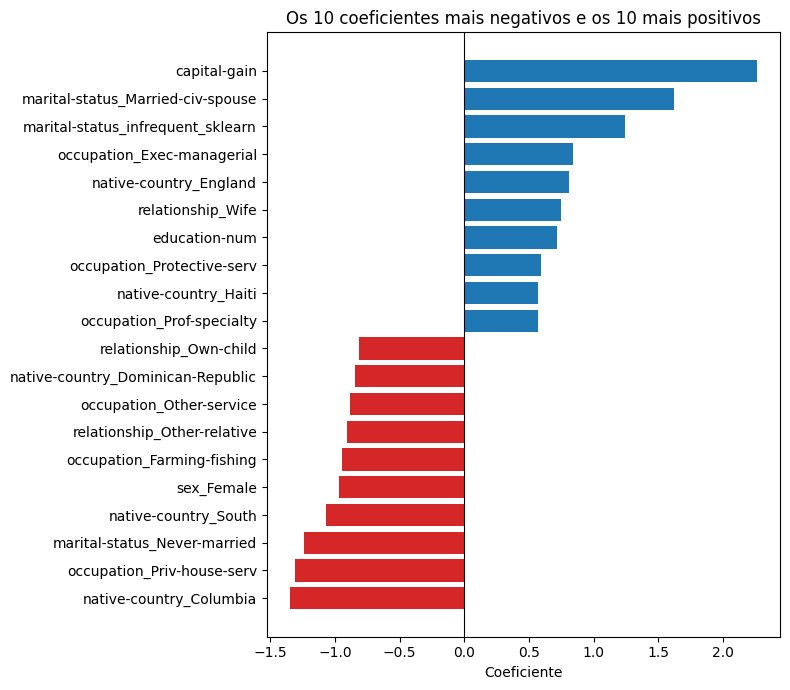

Coeficientes de sex:
sex_Female   -0.969
sex_Male     -0.248


In [17]:
coeficientes = pd.Series(
    logistica_raras.named_steps["modelo"].coef_[0],
    index=nomes_raras,
).sort_values()

# Os nomes vêm como "categoricas__marital-status_Married-civ-spouse"; removemos o prefixo da etapa.
coeficientes.index = coeficientes.index.str.replace("numericas__", "").str.replace("categoricas__", "")

# pd.concat junta duas Series uma embaixo da outra: os 10 menores e os 10 maiores coeficientes.
extremos = pd.concat([coeficientes.head(10), coeficientes.tail(10)])

fig, ax = plt.subplots(figsize=(8, 7))
cores = ["tab:red" if valor < 0 else "tab:blue" for valor in extremos]
ax.barh(extremos.index, extremos.values, color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente")
ax.set_title("Os 10 coeficientes mais negativos e os 10 mais positivos")
plt.tight_layout()
plt.show()

print("Coeficientes de sex:")
print(coeficientes[coeficientes.index.str.startswith("sex_")].round(3).to_string())

**Conclusão:** - **Os maiores coeficientes positivos** são os esperados: `capital-gain` (2,26), estar casado (`Married-civ-spouse`, 1,62), gerentes (`Exec-managerial`) e escolaridade. Do lado negativo aparecem nunca ter casado (`Never-married`), serviços domésticos (`Priv-house-serv`), outros serviços e filhos (`Own-child`).
- **Os coeficientes de uma mesma coluna só fazem sentido comparados entre si.** Cada pessoa tem exatamente uma categoria "acesa" em `sex`, então o que importa é a **diferença**: `sex_Male` (−0,248) menos `sex_Female` (−0,969) = **0,72**. Ser homem, com tudo o mais igual, aumenta a pontuação $z$ em 0,72, ou seja, multiplica a **chance** de renda alta por $e^{0{,}72} \approx 2{,}06$ (a razão de chances do notebook 02): a chance **dobra**. O modelo aprendeu a desigualdade que vimos no notebook 01 e **vai usá-la** nas previsões. Voltaremos a isso no notebook final.
- ⚠️ **Cuidado com os países:** `Columbia`, `South`, `Dominican-Republic`, `England` e `Haiti` aparecem entre os coeficientes mais extremos, mas cada um tem só de 60 a 102 pessoas no treino. Coeficientes grandes aprendidos com poucas pessoas são pouco confiáveis, e a seção 5 mostrou que o país, como um todo, quase não melhora o modelo. O mesmo vale para `marital-status_infrequent_sklearn`, que reúne poucas pessoas de `Married-AF-spouse`.

## 11. Resumo e próximos passos

**Resultados (validação cruzada no treino)**

| Modelo | Acurácia | Renda alta encontrada |
|---|---|---|
| Só numéricas (nb 02) | 81,28% | 38,2% |
| Numéricas + categóricas numeradas | 82,32% | 44,5% |
| Numéricas + one-hot | 85,14% | 60,0% |
| **Numéricas + one-hot (raras agrupadas)** | **85,15% ± 0,47%** | **60,0%** |
| ... + `education` | 85,13% | 59,9% |
| ... + log no capital | 84,54% | 59,0% |

**Conceitos que você aprendeu**
- **Codificação de categorias:** ordinal (inventa uma ordem) × **one-hot** (uma coluna de 0/1 por categoria).
- **Imputação** de valores ausentes, e a categoria **"Desconhecido"** quando a ausência é informativa.
- **`ColumnTransformer`:** tratamentos diferentes para colunas diferentes, tudo dentro do `Pipeline`.
- **Categorias raras** (`min_frequency`) e **categorias nunca vistas** (`handle_unknown`).
- Como ler os **coeficientes de colunas one-hot**: só a diferença dentro da mesma coluna importa.
- Uma técnica que ajudou em outro problema (o logaritmo) **pode piorar** este. Sempre teste.

**Python novo:** `OrdinalEncoder`, `OneHotEncoder` (`sparse_output`, `min_frequency`, `handle_unknown`), `get_feature_names_out`, `SimpleImputer`, `ColumnTransformer`, `set_params` com `__`, `try`/`except`, `pd.concat`, `.str.replace`, `.str.startswith`, list comprehension com `if` e `iloc[[0]]`.

**O que ainda incomoda**
- ⚠️ Mesmo com 85% de acurácia, o modelo ainda **deixa escapar 40%** das pessoas de renda alta.
- ⚠️ Estamos medindo tudo com a **acurácia** e com uma "porcentagem encontrada" improvisada. Precisamos de **métricas próprias** para a classe positiva e de um jeito de escolher o **limiar** de decisão (que ainda está fixo em 0,5).

**Próximo notebook (04):** métricas de classificação. Vamos dar nome aos bois: **precisão**, **recall** e **F1**. Também vamos aprender a **mover o limiar** para trocar alarmes falsos por casos encontrados, e as curvas **ROC** e **precisão-recall**, que avaliam o modelo em **todos** os limiares de uma vez.